# Mishin EAM1势对单晶铜300–800 K热膨胀行为的预测与数值验证

**作者：**【填写全体组员姓名】　**单位：**【填写学校及学院】

## 摘要

为评价经验势对铜有限温度膨胀的预测能力，采用LAMMPS与Mishin EAM1势，对4000原子的周期性面心立方单晶铜进行300–800 K零目标外压NPT模拟。六个温度点分别开展三次独立重复，并在温区端点检查体系尺寸、积分步长及采样时长的影响。晶格常数由300 K的3.63193 Å增至800 K的3.66441 Å，对应线膨胀0.8944%、体积增加2.7074%。温区工程平均线膨胀系数为17.888×10⁻⁶ K⁻¹，三次重复的95%统计区间半宽为0.015×10⁻⁶ K⁻¹；以统一至300 K的NIST SRM 736数据为参考，预测偏差为−3.85%。三项参数检查引起的系数变化均不足0.1%，小于实验比较中的偏差。结果表明，该势再现了所研究温区的正热膨胀趋势，但数值稳定性不等同于实验准确度，现有证据尚不能唯一确定偏差的物理来源。

**关键词：**单晶铜；分子动力学；嵌入原子法；热膨胀；数值验证

## 1 引言

铜在温度变化下的尺寸响应是理解材料热失配和热应力的基础。Alper与Politzer以微电子金属/介质体系为背景，采用有限温度模拟检验体相铜的膨胀等热学性质[1]。这类问题要求模型不仅给出正确的结构，还能够描述温度变化时的平衡体积。对于周期性单晶，晶格常数和体积提供了可直接统计的观测量，因此适合作为评价原子间相互作用模型的切入点。

铜的热膨胀已有不同计算路线，评价时需要区分相互作用模型与有限温度处理方式。Narasimhan与de Gironcoli采用密度泛函理论、密度泛函微扰理论及准谐近似研究铜的热学性质，并比较交换关联近似的影响[2]。热膨胀与非谐响应相关，准谐方法通过声子频率的体积依赖描述这一效应，经典MD则在给定势能面上采样有限温度响应。Lysogorskiy等将NPT热膨胀用于铜势模型比较[3]。这些路线说明，模型复杂度本身不能替代目标物性的实际验证。

经验势MD能够以较低计算成本采样有限温度下的原子运动，其适用性仍取决于具体材料状态与势参数。Olsson等采用Mishin势研究单晶、非晶及纳米晶铜的膨胀，并结合电子结构计算解释不同微结构的差别[4]。Mishin等原始工作则主要针对铜的结构稳定性和缺陷性质构建与检验EAM势[5]。因此，文献中的良好表现可作为选势依据，却不能直接证明本项目温区平均系数的准确程度。

本文将目标限定为Mishin EAM1对300–800 K理想周期单晶铜的热膨胀预测评价。通过独立温度采样得到晶格常数、体积和温区平均系数，再以端点尺寸、步长及时间检查约束数值敏感性。实验比较采用明确参考温度的长度变化数据，以减少定义差异造成的混淆。研究重点是区分可观察的数值影响与仍然存在的实验偏差，而不将既有热膨胀规律表述为新的物理发现。

## 2 计算方法

### 2.1 晶体模型与相互作用

模型由10×10×10个FCC常规晶胞构成，共4000个Cu原子，盒轴依次沿[100]、[010]和[001]方向，三个方向均采用周期性边界。初始晶格常数为3.615 Å，采用共轭梯度法同时弛豫原子坐标与盒子尺寸。静态检查得到4000个FCC环境原子，弛豫后晶格常数约3.61500 Å。该结构表示体相周期近似，不含初始晶界或自由表面，其边界条件决定了后续结果不能直接代表纳米颗粒的膨胀。

原子相互作用采用Mishin等的铜EAM1势[5]，由LAMMPS执行积分[6]。EAM总能量写为

$$E=\sum_i F(\rho_i)+\frac{1}{2}\sum_{i\ne j}\phi(r_{ij}),\qquad
\rho_i=\sum_{j\ne i}f(r_{ij}),\tag{1}$$

其中$F$为嵌入能，$\rho_i$为周围原子贡献的局域密度，$\phi$为对相互作用项。使用NIST条目中明确标为EAM1的`Cu01.eam.alloy`文件，通过`eam/alloy`调用[7]。该选择固定了相互作用模型；本文评价其预测结果，不重新拟合势参数，也不以其他势的文献结果代替实际对照计算。

### 2.2 有限温度模拟协议

在300、400、500、600、700和800 K分别独立生成初速度，而非将同一条轨迹连续升温。每点采用三个不同随机种子，在NPT系综下将标量目标压力设为0 bar，盒长按各向同性方式变化。使用LAMMPS的Nosé–Hoover型温压控制与积分实现[8]，不对同一组原子叠加另一积分器。正式采样前舍弃200 ps平衡段，随后统计500 ps，以避免将初始晶胞调整过程混入均值。

**表1　主计算及端点检查条件。** 两个端点均执行三项检查，每项保持未列出的主计算参数不变；检查轨迹不并入三次正式重复。

|项目|主计算设置|端点检查设置|
|---|---|---|
|结构与原子数|FCC；4000原子；三向周期边界|尺寸检查为12³晶胞，6912原子|
|温度与重复|300–800 K，间隔100 K；每点3次|300、800 K，各条件每点1次|
|目标压力及盒子|0 bar；各向同性调整|不变|
|时间步|1 fs|步长检查为0.5 fs|
|温度/压力阻尼|0.1 ps / 1 ps|不变|
|平衡与采样|200 ps + 500 ps|时长检查为1000 ps + 1000 ps|
|标量输出间隔|0.1 ps|不变|
|计算量|18条正式轨迹|6条检查轨迹|

In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
from IPython.display import display, Image
from run_study import manifest, folder
from analyze_study import read_job, reference
from md_project import plotting
jobs = manifest()
checked = [read_job(job)[0] for job in jobs]
assert len(checked) == 24
for job in jobs:
    meta = json.loads((folder(job)/"metadata.json").read_text(encoding="utf8"))
    text = (folder(job)/"input.in").read_text(encoding="ascii")
    assert hashlib.sha256(text.encode("ascii")).hexdigest() == meta["input_sha256"]
figdir = Path("results/paper_figures"); figdir.mkdir(exist_ok=True)
plt = plotting()
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
# 展示实际使用的建模与积分设置，不在论文中重跑MD。
for file in ["outputs/model/build.in", "outputs/production/prod_T300_r1/input.in"]:
    text = Path(file).read_text(encoding="ascii")
    keys = ("lattice ", "region ", "boundary ", "pair_style ", "pair_coeff ", "timestep ", "fix integrator ", "run ")
    print("\n" + file)
    print("\n".join(line for line in text.splitlines() if line.startswith(keys)))


outputs/model/build.in
boundary p p p
lattice fcc 3.615
region box block 0 10 0 10 0 10 units lattice
pair_style eam/alloy
pair_coeff * * potentials/Cu01.eam.alloy Cu
run 0

outputs/production/prod_T300_r1/input.in
boundary p p p
pair_style eam/alloy
pair_coeff * * potentials/Cu01.eam.alloy Cu
timestep 0.001
fix integrator all npt temp 300 300 0.1 iso 0 0 1
run 200000
run 500000


### 2.3 观测量与实验基准

对每条轨迹，逐帧以$a=L_x/n$计算晶格常数，其中$n$为盒长方向的常规晶胞数，再对平衡期之后的数据求均值。立方盒的三个边长同步变化，体积则直接读取并独立统计。以300 K为参考，定义线膨胀$\epsilon(T)$及工程温区平均系数：

$$\epsilon(T)=\frac{\bar a(T)-\bar a(300)}{\bar a(300)},\qquad
\bar\alpha_{300-800}=\frac{\epsilon(800)}{800-300}.\tag{2}$$

式（2）是端点割线量，不是瞬时系数$\alpha(T)=a(T)^{-1}\mathrm{d}a/\mathrm{d}T$。六个温度点用于描述变化趋势，主系数由两端点获得；本文不通过高阶拟合推断精细的瞬时温度依赖，以免增加数据尚不足以约束的解释。

实验参考取自1990年修订的NIST SRM 736证书[9]，相关原始测量研究见Hahn[10]。证书给出相对293 K的长度变化$e_{293}(T)$，比较前按

$$\epsilon_{\mathrm{ref}}(T)=\frac{1+e_{293}(T)}{1+e_{293}(300)}-1\tag{3}$$

统一到300 K。采用表中300 K的117 ppm和800 K的9420 ppm，得到同定义平均系数18.6038×10⁻⁶ K⁻¹。使用修订表而不混用旧表或室温单点值，使模拟与参考在温区、分母和单位上保持一致。

### 2.4 统计与参数检查

连续轨迹中的相邻样本存在相关性，不能将5000个输出点视作5000次独立实验。依据相关数据误差分析方法[11,12]，将轨迹按1、2、5、10、20和50 ps分块，观察块长改变时均值标准误的敏感性；以20 ps块计算单轨迹误差，并比较前后半段。最终系数分别由三组独立端点重复计算，报告其均值及基于$t$分布、自由度2的95%统计区间。这一近似依赖独立重复与均值分布假设，且未包含实验或模型系统误差。

参数检查将300和800 K的原子数增至6912、步长减至0.5 fs，或平衡与采样各延长至1 ns。各项平均系数分别与正式重复r1比较，沿用计算前确定的±2%实用目标。该目标用于筛查当前协议的参数敏感性，不是普适收敛标准，也不是统计显著性检验；中间温度没有进行同等完整的参数扫描。

In [3]:
runs = pd.DataFrame(checked)
prod = runs[runs.group == "production"]
a = prod.pivot(index="temperature", columns="replicate", values="a_A")
v = prod.pivot(index="temperature", columns="replicate", values="volume_A3")
eps = a.div(a.loc[300], axis=1) - 1
alpha = eps.loc[800] / 500
tcrit = 4.3026527299
estimate = alpha.mean()
halfwidth = tcrit * alpha.std(ddof=1) / np.sqrt(3)
ref, refalpha = reference()
bias = 100 * (estimate / refalpha - 1)
checks = pd.read_csv("results/validation_comparison.csv")
assert np.isclose(estimate * 1e6, 17.8882558243, rtol=1e-8)
print(f"平均系数 = {estimate*1e6:.3f} ± {halfwidth*1e6:.3f} ×10⁻⁶ K⁻¹（95%统计区间）")
print(f"NIST = {refalpha*1e6:.4f} ×10⁻⁶ K⁻¹；相对偏差 = {bias:.2f}%")

平均系数 = 17.888 ± 0.015 ×10⁻⁶ K⁻¹（95%统计区间）
NIST = 18.6038 ×10⁻⁶ K⁻¹；相对偏差 = -3.85%


## 3 结果与讨论

### 3.1 晶格与体积的温度响应

六个温度点的平均晶格常数均随温度上升，呈现正热膨胀（图1）。300和800 K的结果分别为3.63193和3.66441 Å，端点差约0.03248 Å，对应相对线膨胀0.8944%。均值的变化明显大于三次重复的统计波动，因此升温引起的尺度增长在当前采样下可以分辨。图中连线只连接离散计算点，不表示额外拟合模型。

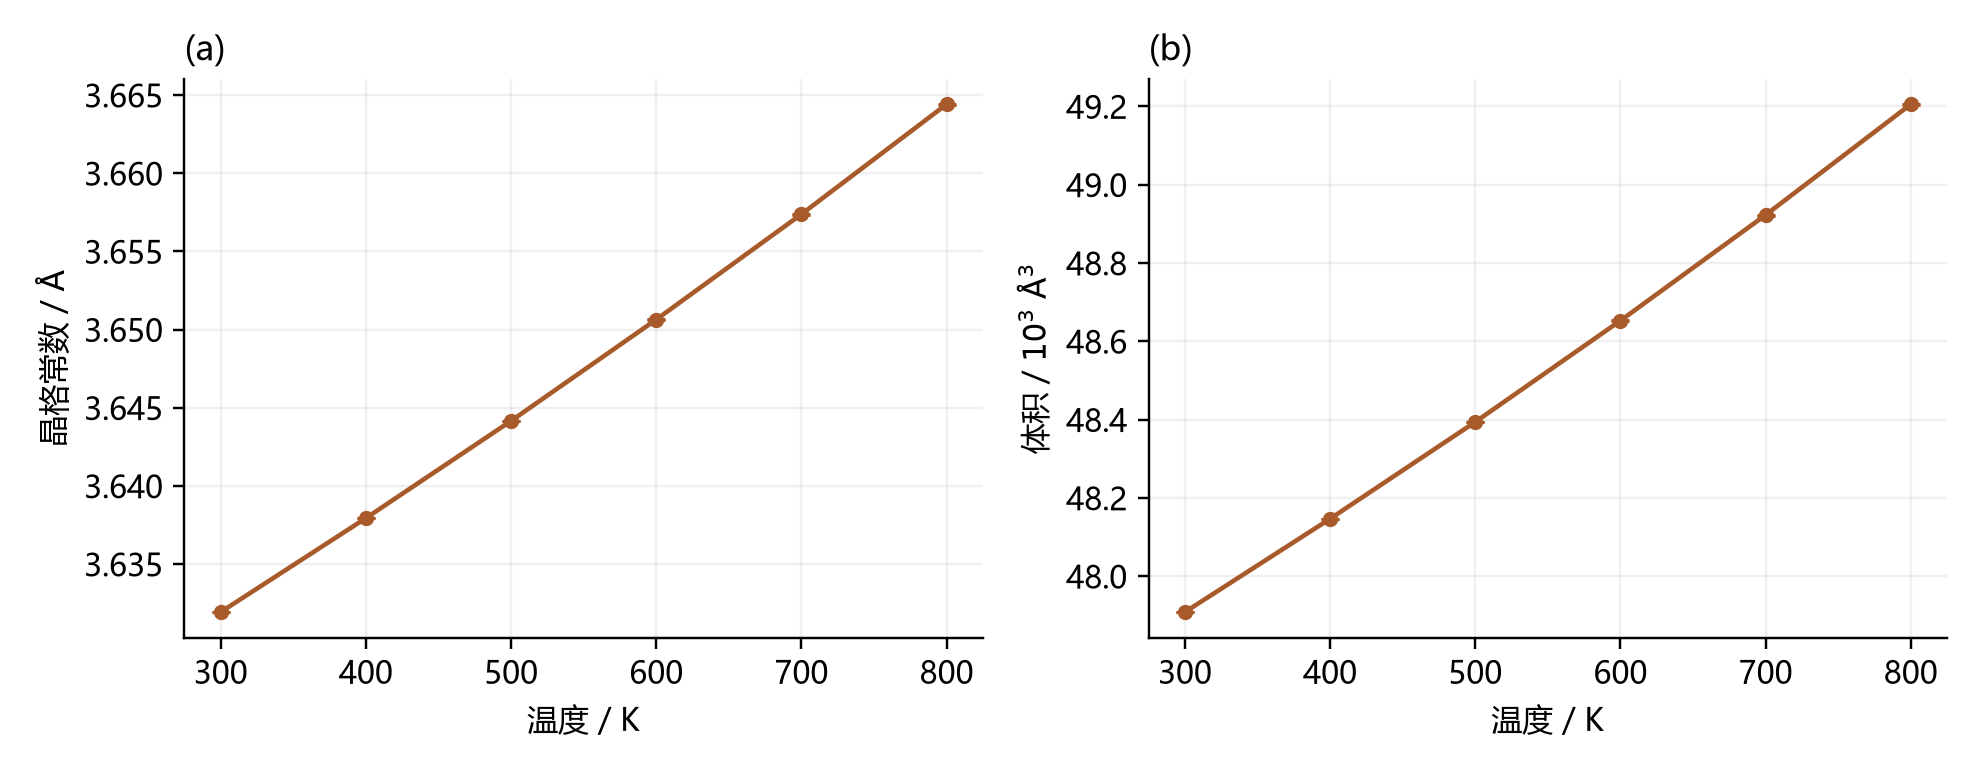

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
for panel, data, scale, ylabel in [(ax[0], a, 1, "晶格常数 / Å"), (ax[1], v, 1e-3, r"体积 / $10^3$ Å$^3$")]:
    panel.errorbar(data.index, data.mean(axis=1)*scale, yerr=tcrit*data.std(axis=1)/np.sqrt(3)*scale,
                   fmt="o-", color="#a85a2a", capsize=3, ms=4)
    panel.set(xlabel="温度 / K", ylabel=ylabel)
    panel.grid(alpha=.18)
for panel, tag in zip(ax, ["(a)", "(b)"]): panel.set_title(tag, loc="left", fontsize=11)
fig.tight_layout()
fig.savefig(figdir/"figure1_lattice_volume.png", dpi=220)
display(Image(filename=str(figdir/"figure1_lattice_volume.png"))); plt.close(fig)

**图1　单晶铜晶格常数与体积随温度的变化。** （a）晶格常数；（b）盒子体积。每个点为三次独立重复的均值，误差棒为自由度2的95%统计区间，部分误差棒小于符号尺寸。体积由LAMMPS输出逐帧平均，而非将平均晶格常数直接立方；折线仅用于引导视线。

体积由约47908.4 Å³增至49205.5 Å³，增加2.7074%，与线膨胀方向一致。对于当前保持立方形状的盒子，小应变近似下体积相对变化约为线膨胀的三倍；有限应变项和平均运算的非交换性使两者无需严格满足三倍关系。因而，体积结果提供的是与盒长统计一致的几何核查，而非独立的势函数准确度证明。

### 3.2 同参考温度下的实验比较

统一参考温度后，模拟和NIST数据均随温度上升，但模拟线膨胀逐渐低于参考（图2）。两条曲线在300 K重合由归一化定义决定，不能作为该温度预测准确的独立证据。到800 K，线膨胀差约为−358 ppm，对应工程平均系数差约−0.716×10⁻⁶ K⁻¹。用残差展示这一差异，比仅凭两条接近的曲线判断“吻合良好”更能说明模型的实际表现。

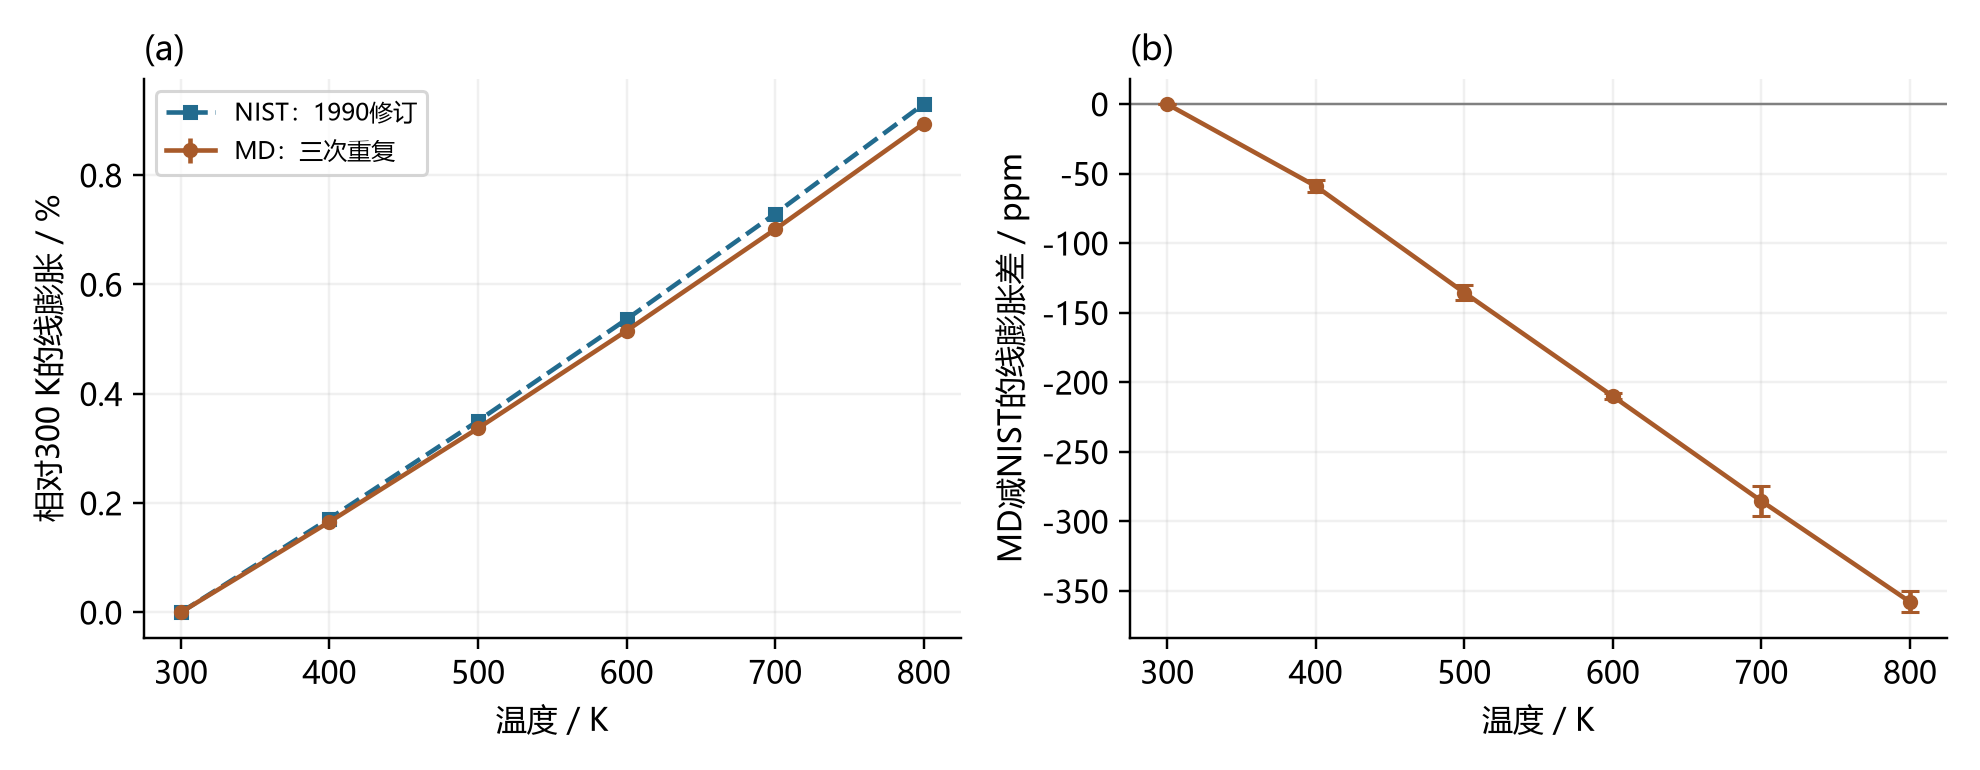

In [5]:
mean_eps = eps.mean(axis=1)
ci_eps = tcrit * eps.std(axis=1) / np.sqrt(3)
reference_eps = ref.set_index("temperature_K").strain_from_300.reindex(eps.index)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
ax[0].errorbar(eps.index, mean_eps*100, yerr=ci_eps*100, fmt="o-", color="#a85a2a", ms=4, label="MD：三次重复")
ax[0].plot(eps.index, reference_eps*100, "s--", color="#226b8e", ms=4, label="NIST：1990修订")
ax[0].set(xlabel="温度 / K", ylabel="相对300 K的线膨胀 / %")
ax[0].legend(fontsize=8)
ax[1].axhline(0, color="gray", lw=.8)
ax[1].errorbar(eps.index, (mean_eps-reference_eps)*1e6, yerr=ci_eps*1e6,
               fmt="o-", color="#a85a2a", capsize=3, ms=4)
ax[1].set(xlabel="温度 / K", ylabel="MD减NIST的线膨胀差 / ppm")
for panel, tag in zip(ax, ["(a)", "(b)"]):
    panel.set_title(tag, loc="left", fontsize=11); panel.grid(alpha=.18)
fig.tight_layout()
fig.savefig(figdir/"figure2_reference_residual.png", dpi=220)
display(Image(filename=str(figdir/"figure2_reference_residual.png"))); plt.close(fig)

**图2　模拟与NIST修订表的归一化线膨胀对照。** （a）相对300 K的长度变化；（b）模拟减参考的差值，单位ppm。残差误差棒仅来自三次MD重复，并按各重复自身300 K长度归一化，以保留共享基准造成的相关性；未传播参考表的测量与舍入不确定度。NIST数据来自证书第1页[9]。

**表2　300–800 K工程平均线膨胀系数比较。** 系数及区间半宽的单位均为10⁻⁶ K⁻¹。MD点估计是三组重复系数的均值；相对偏差以NIST值为分母。参考项未给出经本文传播的统计区间，不应将空缺理解为零不确定度。

In [6]:
table = pd.DataFrame({"项目": ["MD：三次重复", "NIST SRM 736修订表"],
    "平均系数": [f"{estimate*1e6:.3f}", f"{refalpha*1e6:.4f}"],
    "95%统计区间半宽": [f"{halfwidth*1e6:.3f}", "未作联合传播"],
    "相对NIST偏差": [f"{bias:.2f}%", "参考基准"]})
display(table.style.hide(axis="index"))

项目,平均系数,95%统计区间半宽,相对NIST偏差
MD：三次重复,17.888,0.015,-3.85%
NIST SRM 736修订表,18.6038,未作联合传播,参考基准


三次重复所得平均系数约为17.885、17.895和17.885×10⁻⁶ K⁻¹，汇总值17.888×10⁻⁶ K⁻¹较参考低3.85%（表2）。其统计区间远窄于模拟与参考的差异，表明重复初速度导致的随机波动不足以解释当前差值。然而，三次重复只能有限地估计抽样分布，且参考数据来自实际高纯铜试样；因此，区间不能用于宣称模型具有同等水平的实验准确度。

### 3.3 平衡表现与数值敏感性

24条轨迹在采样阶段的平均温度与目标的最大绝对差为0.249 K，平均压力范围为−7.57至5.85 bar。端点时间序列中温度、能量和体积保持波动，未表现为持续单向增长（图S1）；前后半段晶格均值差除以其分块标准误的最大比值为2.246。这些诊断未触发当前流程的强漂移复核条件，但零目标外压并不要求每帧或有限时长均压精确为零，均值接近目标也不能单独证明充分采样。

尺寸、步长和时长改变后，平均系数相对基准r1分别变化+0.0680%、−0.0087%和+0.0280%，均小于预设±2%目标（图3）。尤其是将步长减半后结果变化较小，未显示在当前精度下明显的步长敏感性。三项检查仍各只有一组端点轨迹，故它们支持当前计算协议的有限稳健性，而不能给出全部离散化、有限尺寸或采样误差的严格上界。

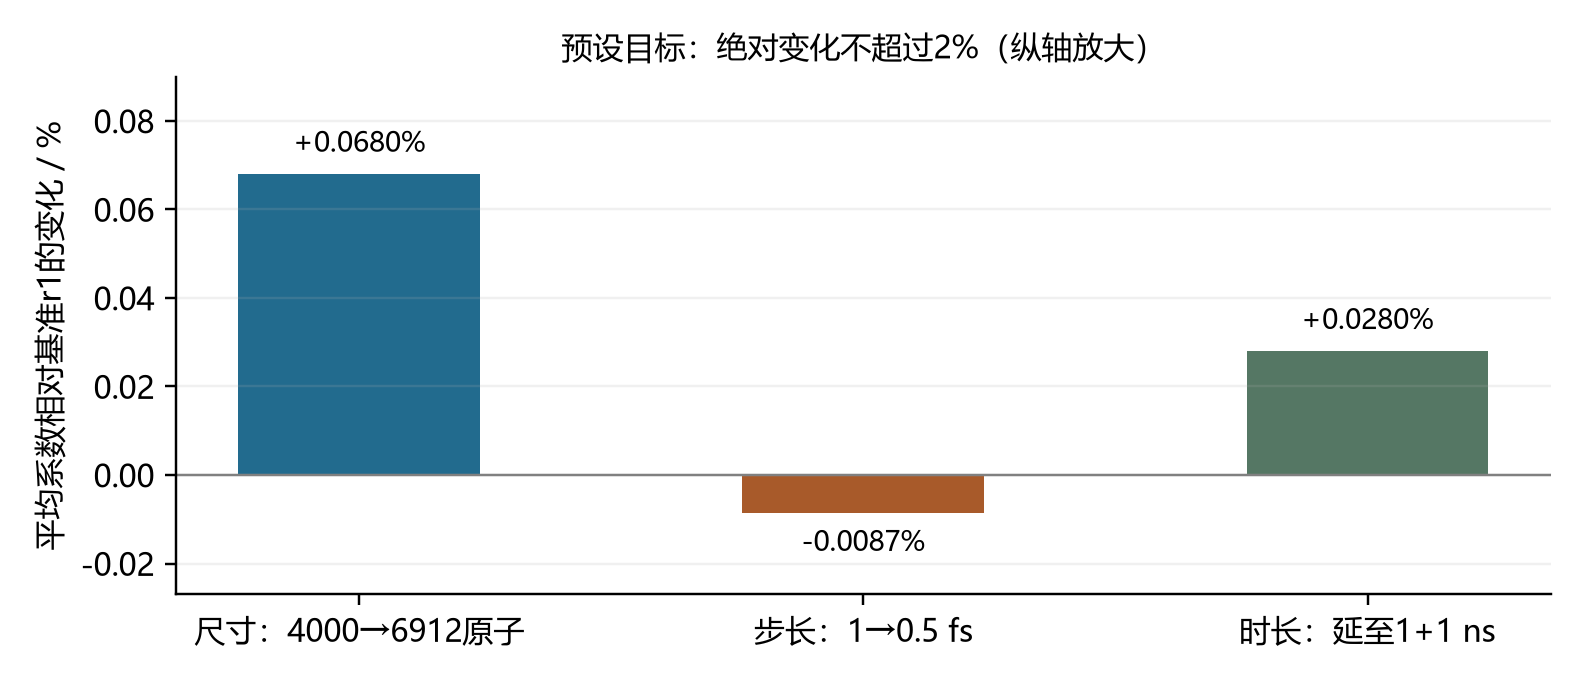

In [7]:
fig, ax = plt.subplots(figsize=(7.2, 3.1))
bars = ax.bar(["尺寸：4000→6912原子", "步长：1→0.5 fs", "时长：延至1+1 ns"], checks.change_percent,
              color=["#226b8e", "#a85a2a", "#557764"], width=.48)
ax.axhline(0, color="gray", lw=.8)
ax.bar_label(bars, labels=[f"{x:+.4f}%" for x in checks.change_percent], padding=5, fontsize=9)
ax.set(ylabel="平均系数相对基准r1的变化 / %", ylim=(-.027, .09))
ax.set_title("预设目标：绝对变化不超过2%（纵轴放大）", fontsize=10)
ax.grid(axis="y", alpha=.18)
fig.tight_layout(); fig.savefig(figdir/"figure3_sensitivity.png", dpi=220)
display(Image(filename=str(figdir/"figure3_sensitivity.png"))); plt.close(fig)

**图3　端点参数变化对温区平均系数的影响。** 各项均与正式计算r1端点系数比较，未与三次重复汇总值混用。每项含300、800 K各一条轨迹，无独立重复区间，故不绘制置信误差棒。纵轴放大显示小幅变化，预设±2%目标超出所示范围；数值标签给出实际变化率。

分块检查与上述端点结果相互补充。块长由20增至50 ps时，24条轨迹的均值标准误比值中位数为1.018，范围0.564–1.299，未见一致的继续增大（图S2展示端点r1）。这降低了将高频相关样本直接视为独立样本的风险，但更长块也减少了块数，误差估计自身会波动。因此，块长敏感性是当前不确定度评估的诊断证据，不应被表述为相关性已完全消除。

### 3.4 模型表现与解释边界

本研究的实验偏差显著大于所检查参数引起的系数变化，因而仅调整这些数值条件不足以消除当前差值。结合Mishin势在结构稳定性与缺陷方面的原始验证[5]，更合理的判断是：静态或其他物性上的适用性不能自动迁移为热膨胀的完全准确。现有检查没有分别量化势函数近似、参考试样差别等贡献，故不能将剩余差值唯一归因于某个势函数非谐项。

文献比较同样需要保持定义和对象一致。Lysogorskiy等将铜的NPT热膨胀曲线用于多势验证[3]，支持这一物性作为评价工具；Narasimhan与de Gironcoli比较的是随温度变化的系数与不同近似[2]，其单点偏差不等于本文温区平均偏差。Olsson等进一步研究晶界与非晶组分[4]，而本模型没有这些微结构。由此可以比较研究路线与趋势，却不能据现有资料给不同势或不同理论方法排统一的精度名次。

当前结论还受观测量与模型边界限制。归一化膨胀比较消除了常数基准长度的差别，不能据此独立确认绝对晶格常数的准确性；经典MD未显式处理核量子和电子热激发，初始完美周期结构也不等同于真实试样。本文未系统追踪有限温度缺陷或计算声子与电子结构，因此不能从标量膨胀曲线反推唯一微观机制。这些限制界定了本次势函数评价的范围，也给出了后续扩展所需的证据类型。

## 4 结论

在Mishin EAM1、零目标外压及周期单晶条件下，300–800 K的晶格常数和体积均随温度增加，端点线膨胀为0.8944%。工程平均线膨胀系数为17.888×10⁻⁶ K⁻¹，三次重复的95%统计区间半宽为0.015×10⁻⁶ K⁻¹，比同定义NIST参考低3.85%。尺寸、步长与时长检查引起的系数变化均不足0.1%，表明当前实验差值不能仅由已检查的数值条件解释。该结果支持将模型用于所研究温区内的趋势描述，同时保留其相对参考数据的定量偏差；进一步归因需要独立的势模型或微观物性对照，而非仅延长现有曲线的解释。

统计区间仅表征三次独立重复的波动，端点检查也未覆盖所有温度和参数组合。因而，本文支持在限定条件下使用该势描述膨胀趋势，并以所报告偏差评价定量结果，不将小统计误差或参数目标通过解释为模型无偏。

## 数据与代码可用性

原始标量、输入文件、元数据和分析代码保存于[公开项目仓库](https://github.com/Gytid8/copper-thermal-expansion)。本Notebook仅读取并复算现有数据，不自动重启长时间MD。两条步长验证从平衡点恢复后重新采满500 ps，重复边界行的原始文件与清理记录均已保留，详见[恢复记录](https://github.com/Gytid8/copper-thermal-expansion/blob/main/docs/recovery_record.md)。作者姓名、单位及实际贡献须由组员据实填写。

## 参考文献

[1] Alper H. E., Politzer P. Molecular dynamics simulation of the temperature-dependent behavior of solid copper. *Journal of Molecular Structure: THEOCHEM*, 487, 117–125 (1999). [DOI:10.1016/S0166-1280(99)00147-5](https://doi.org/10.1016/S0166-1280(99)00147-5).

[2] Narasimhan S., de Gironcoli S. Ab initio calculation of the thermal properties of Cu: Performance of the LDA and GGA. *Physical Review B*, 65, 064302 (2002). [DOI:10.1103/PhysRevB.65.064302](https://doi.org/10.1103/PhysRevB.65.064302); [作者公开稿](https://arxiv.org/abs/cond-mat/0109020).

[3] Lysogorskiy Y., van der Oord C., Bochkarev A., et al. Performant implementation of the atomic cluster expansion (PACE) and application to copper and silicon. *npj Computational Materials*, 7, 97 (2021). [DOI:10.1038/s41524-021-00559-9](https://doi.org/10.1038/s41524-021-00559-9); [作者公开稿](https://arxiv.org/abs/2103.00814).

[4] Olsson P. A. T., Awala I., Holmberg-Kasa J., et al. Grain Size-Dependent Thermal Expansion of Nanocrystalline Metals. *Materials*, 16, 5032 (2023). [DOI:10.3390/ma16145032](https://doi.org/10.3390/ma16145032); [机构公开全文](https://lucris.lub.lu.se/ws/portalfiles/portal/159582754/Olsson_2023c.pdf).

[5] Mishin Y., Mehl M. J., Papaconstantopoulos D. A., Voter A. F., Kress J. D. Structural stability and lattice defects in copper: Ab initio, tight-binding, and embedded-atom calculations. *Physical Review B*, 63, 224106 (2001). [DOI:10.1103/PhysRevB.63.224106](https://doi.org/10.1103/PhysRevB.63.224106).

[6] Thompson A. P., Aktulga H. M., Berger R., et al. LAMMPS—a flexible simulation tool for particle-based materials modeling at the atomic, meso, and continuum scales. *Computer Physics Communications*, 271, 108171 (2022). [DOI:10.1016/j.cpc.2021.108171](https://doi.org/10.1016/j.cpc.2021.108171); [软件官方引用说明](https://www.lammps.org/about/citing/).

[7] NIST Interatomic Potentials Repository. 2001–Mishin et al.–Cu-1，EAM1及LAMMPS势文件转换说明. [官方条目](https://www.ctcms.nist.gov/potentials/entry/2001--Mishin-Y-Mehl-M-J-Papaconstantopoulos-D-A-et-al--Cu-1/)，访问日期2026-10-18.

[8] LAMMPS Documentation. *fix nvt / npt / nph commands*. [官方文档](https://docs.lammps.org/fix_nh.html)，访问日期2026-10-18；本研究实际软件版本为22Jul2025 update4，在线文档可能随发行版更新。

[9] NIST. *Standard Reference Material 736: Copper—Thermal Expansion*. Certificate，1990-10-07修订，第1页表格. [官方历史证书](https://tsapps.nist.gov/srmext/certificates/archives/736.pdf).

[10] Hahn T. A. Thermal Expansion of Copper from 20 to 800 K—Standard Reference Material 736. *Journal of Applied Physics*, 41, 5096–5101 (1970). [DOI:10.1063/1.1658614](https://doi.org/10.1063/1.1658614). 本文数值取自文献[9]修订表，而非旧版表值。

[11] Flyvbjerg H., Petersen H. G. Error estimates on averages of correlated data. *The Journal of Chemical Physics*, 91, 461–466 (1989). [DOI:10.1063/1.457480](https://doi.org/10.1063/1.457480).

[12] Grossfield A., Patrone P. N., Roe D. R., Schultz A. J., Siderius D. W., Zuckerman D. M. Best Practices for Quantification of Uncertainty and Sampling Quality in Molecular Simulations [Article v1.0]. *Living Journal of Computational Molecular Science*, 1(1), 5067 (2019). [DOI:10.33011/livecoms.1.1.5067](https://doi.org/10.33011/livecoms.1.1.5067); [期刊公开全文](https://livecomsjournal.org/index.php/livecoms/article/download/v1i1e5067/913/2595).

## 补充材料

### S1 端点轨迹的平衡诊断

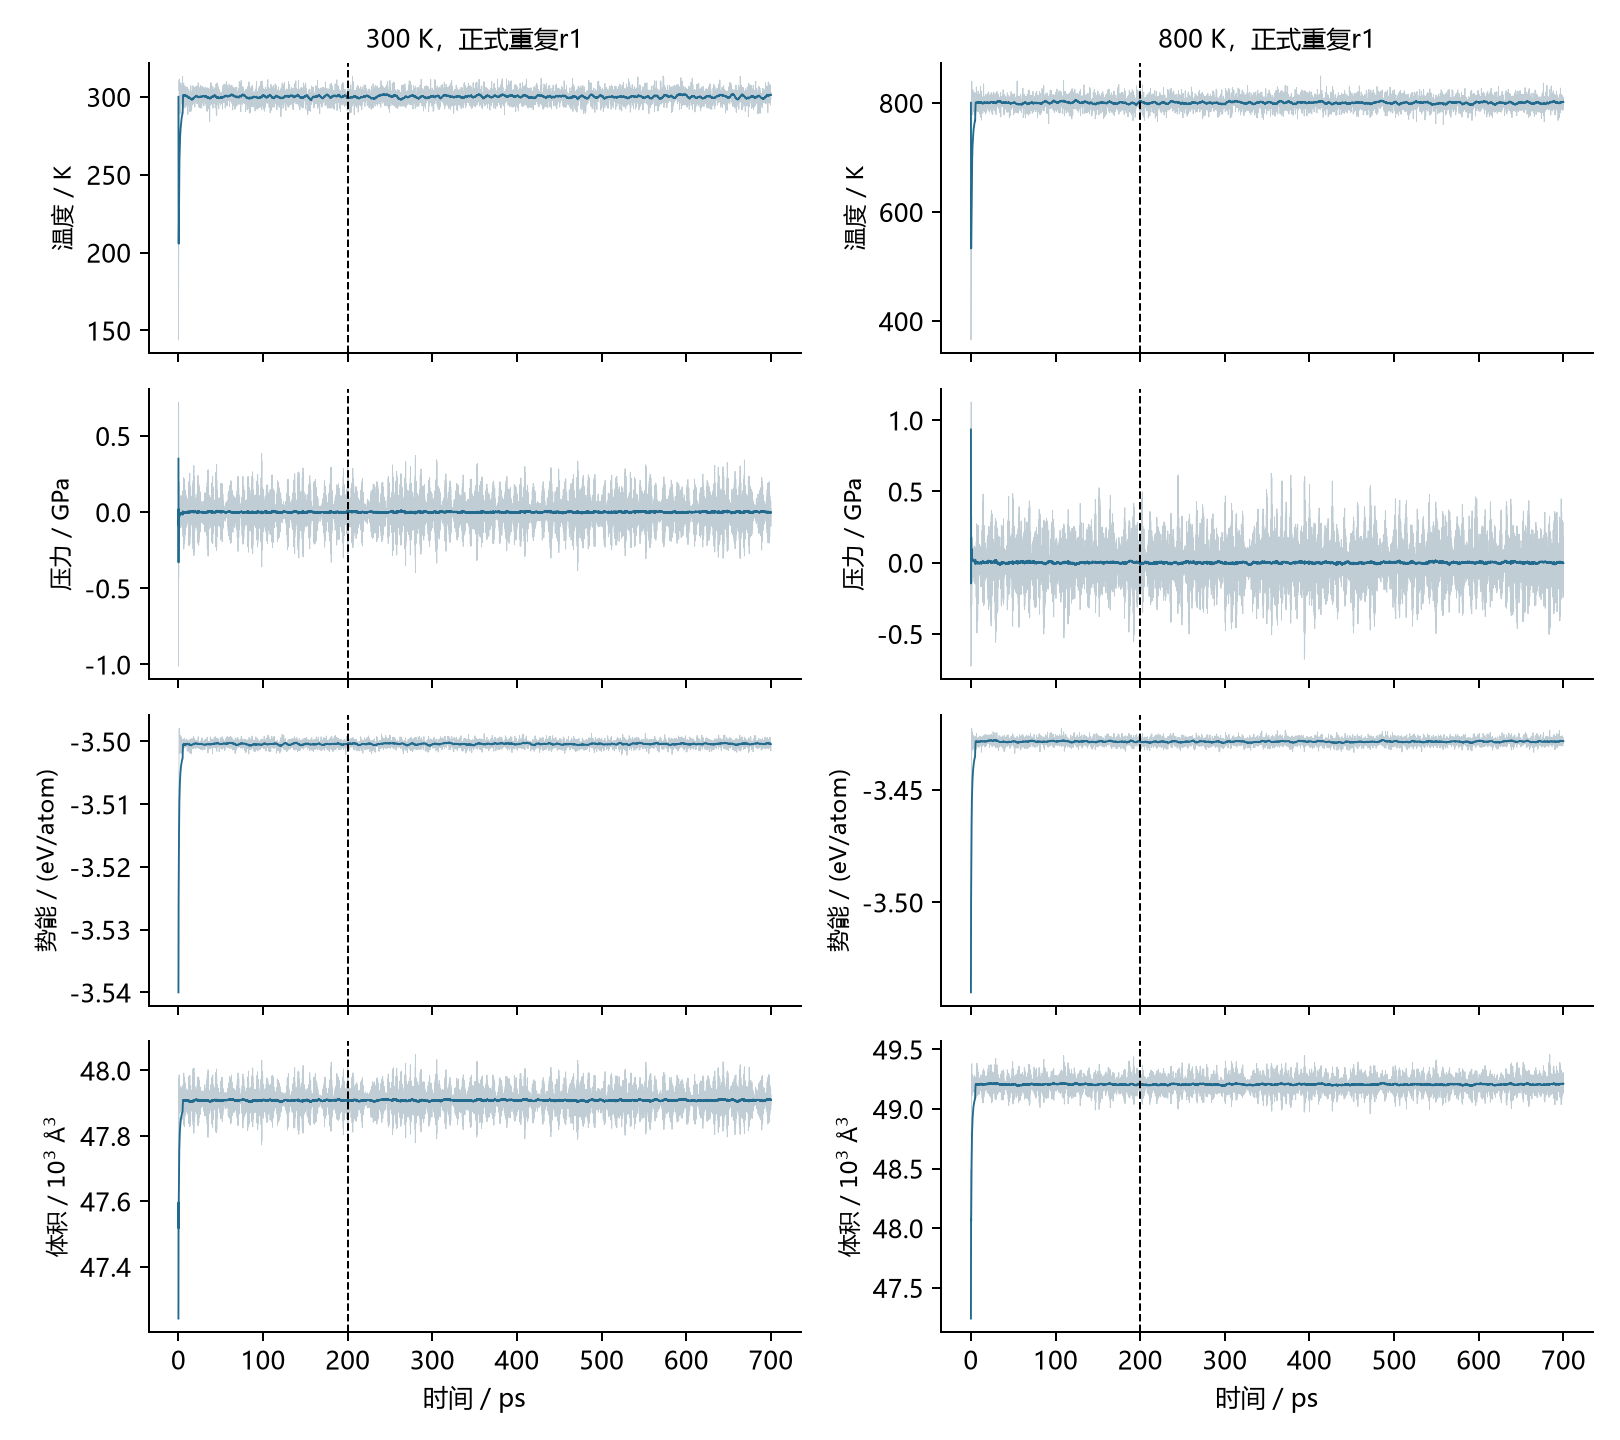

In [8]:
fig, axes = plt.subplots(4, 2, figsize=(9, 8), sharex=True)
keys = ["temperature_K", "pressure_bar", "potential_eV", "volume_A3"]
labels = ["温度 / K", "压力 / GPa", "势能 / (eV/atom)", r"体积 / $10^3$ Å$^3$"]
for col, temp in enumerate([300, 800]):
    job = next(j for j in jobs if j["id"] == f"prod_T{temp}_r1")
    frame = pd.read_csv(folder(job)/"thermo.dat", sep=r"\s+", comment="#", names=
        ["step", "time_ps", "temperature_K", "pressure_bar", "potential_eV", "lx_A", "ly_A", "lz_A", "volume_A3"])
    for row, (key, factor) in enumerate(zip(keys, [1, 1e-4, 1/4000, 1e-3])):
        panel = axes[row, col]; y = frame[key] * factor
        panel.plot(frame.time_ps, y, lw=.35, color="#c0cdd4")
        panel.plot(frame.time_ps, y.rolling(50, min_periods=1).mean(), lw=.75, color="#226b8e")
        panel.axvline(200, color="black", ls="--", lw=.8)
        panel.set_ylabel(labels[row], fontsize=9)
    axes[0, col].set_title(f"{temp} K，正式重复r1", fontsize=10)
    axes[-1, col].set_xlabel("时间 / ps")
fig.tight_layout(); fig.savefig(figdir/"figureS1_endpoint_traces.png", dpi=180)
display(Image(filename=str(figdir/"figureS1_endpoint_traces.png"))); plt.close(fig)

**图S1　300 K与800 K正式重复r1的温度、压力、单原子势能及体积。** 浅线为0.1 ps输出，深线为5 ps移动平均，仅用于展示；竖虚线之后为500 ps统计区间。压力以GPa展示，1 bar=10⁻⁴ GPa；大幅瞬时波动不等于目标压力设置错误。

### S2 分块长度敏感性

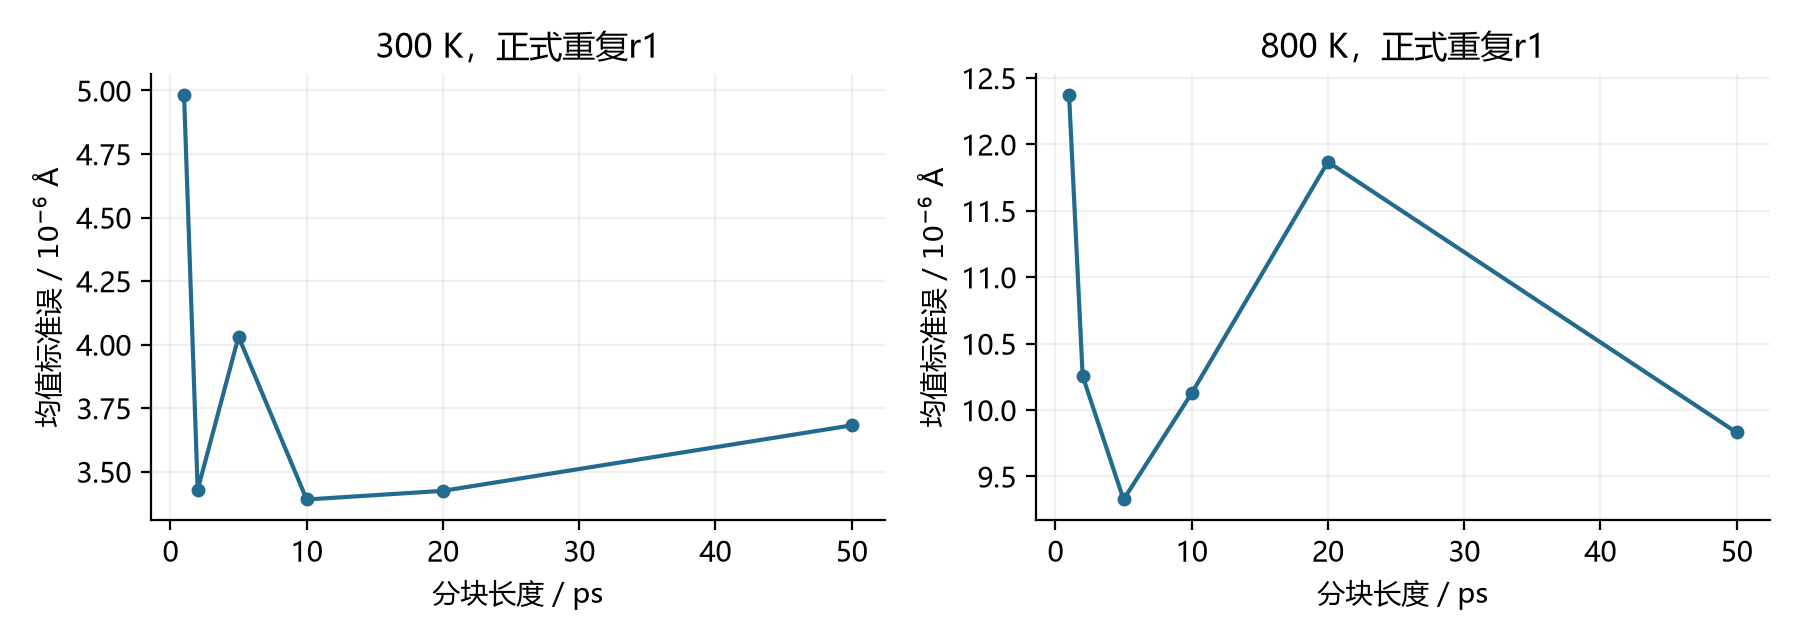

In [9]:
blocks = pd.read_csv("results/block_statistics.csv")
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for panel, temp in zip(axes, [300, 800]):
    block = blocks[blocks.job == f"prod_T{temp}_r1"]
    panel.plot(block.block_ps, block.a_sem_A*1e6, "o-", ms=4, color="#226b8e")
    panel.set(xlabel="分块长度 / ps", ylabel=r"均值标准误 / $10^{-6}$ Å", title=f"{temp} K，正式重复r1")
    panel.grid(alpha=.18)
fig.tight_layout(); fig.savefig(figdir/"figureS2_block_statistics.png", dpi=200)
display(Image(filename=str(figdir/"figureS2_block_statistics.png"))); plt.close(fig)

**图S2　端点正式重复r1的分块统计。** 横轴为块长，纵轴为晶格常数均值标准误；计算时按块求均值，再估计均值标准误。不同块长的块数不同，曲线局部波动不应解释为严格收敛或发散。

所有24条轨迹的分块结果和前后半段检查见`results/block_statistics.csv`与`results/run_summary.csv`。引用核查记录见`docs/reference_verification.json`。运行中断与边界清理不改变正式采样定义，其原始证据保留在项目数据及恢复说明中。